[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_lambda/BA_L7_lambda.ipynb)

# BA_L7_lambda: Monte Carlo: Raw, Half or Full correction of a VaR forecast

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Monte Carlo study of correcting a biased 1% quantile forecast by the empirical quantile of 500 past errors with intensity 0 (Raw), 1/2 (Half) or 1 (Full): excess expected quantile score and expected breach rate against the bias, with the local second-order theory. Student-t(5) returns, 20,000 replications.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## Method

Forecast errors on a calibration window of $n$ days are $e_t = r_t - q_t$. The fitted correction is the empirical $\alpha$-quantile of the errors,
$\hat c = \hat Q_\alpha(e_{t-n}, \dots, e_{t-1})$, and the corrected forecast with intensity $\lambda$ is
$q_t^{(\lambda)} = q_t + \lambda \hat c$, with $\lambda = 0$ (Raw), $\tfrac12$ (Half), $1$ (Full).

Let $\delta$ be the bias of the raw forecast and $\hat c = \delta + \varepsilon$ with $V(\varepsilon) = \sigma_Q^2$. With $f$ the density at the
quantile, a second-order expansion gives the excess expected quantile score (QS)

$$ \Delta(\lambda) \approx \frac f2\left[(1-\lambda)^2\delta^2 + \lambda^2 \sigma_Q^2\right], \qquad \lambda^* = \frac{\delta^2}{\delta^2 + \sigma_Q^2} . $$

Full beats Raw iff $\delta^2 > \sigma_Q^2$; Half beats Full iff $\delta^2 < 3\sigma_Q^2$; Half beats Raw iff $\delta^2 > \sigma_Q^2/3$.

Design: returns i.i.d. Student-$t_5$, $\alpha = 1\%$, $n = 500$; the raw forecast is the true quantile shifted by $\delta$; 20,000 replications.
Left panel: excess expected QS ($\times 10^{-3}$), solid lines Monte Carlo, dashed lines the local theory. Right panel: expected breach rate.
**How to read it**: Half is never far from the best choice; Full pays the estimation noise of a quantile that rests on 5 observations.

sampling sd of the fitted 1% correction, sigma_Q     0.392
Half beats Raw from delta/sigma_Q (Monte Carlo)      0.650
Half beats Raw from delta/sigma_Q (theory)           0.580
Half beats Full up to delta/sigma_Q (Monte Carlo)    1.400
Half beats Full up to delta/sigma_Q (theory)         1.730
Full beats Raw from delta/sigma_Q (Monte Carlo)      0.950
Full beats Raw from delta/sigma_Q (theory)           1.000
no bias: excess expected QS x 1e3, Full              0.920
no bias: expected breach rate with Full (%)          1.190


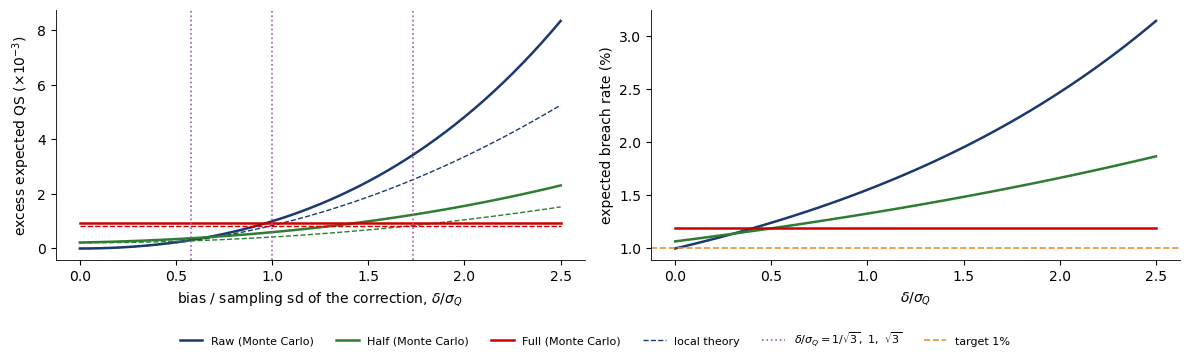

In [4]:
# the slide charts use 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10})
SLIDE_GOLD = '#B8860B'

from scipy import stats

NU, A, NC, REPS = 5, 0.01, 500, 20000
qt5 = stats.t.ppf(A, NU); f5 = stats.t.pdf(qt5, NU)


def Lq(x):
    """Expected quantile score of the constant forecast x under t(NU)."""
    pe = -(NU + x ** 2) / (NU - 1) * stats.t.pdf(x, NU)          # integral of y f(y) up to x
    return A * (0 - x) + x * stats.t.cdf(x, NU) - pe


rng = np.random.default_rng(11)
qhat = np.quantile(stats.t.rvs(NU, size=(REPS, NC), random_state=rng), A, axis=1)
sq = qhat.std(ddof=1)                                            # sampling sd of the fitted correction
ratios = np.linspace(0, 2.5, 51)                                 # delta / sigma_Q
mc = {lam: [] for lam in [0, 0.5, 1]}
br = {lam: [] for lam in mc}
for rr in ratios:
    dlt = rr * sq
    cfit = qhat - qt5 - dlt
    for lam in mc:
        mc[lam].append(1e3 * np.mean(Lq(qt5 + dlt + lam * cfit) - Lq(qt5)))
        br[lam].append(100 * np.mean(stats.t.cdf(qt5 + dlt + lam * cfit, NU)))
mc = {k: np.array(v) for k, v in mc.items()}
theory = {lam: 1e3 * f5 / 2 * ((1 - lam) ** 2 * (ratios * sq) ** 2 + lam ** 2 * sq ** 2) for lam in mc}


def cross(a_, b_):
    d = np.diff(np.sign(a_ - b_)) != 0
    return ratios[np.argmax(d)] if d.any() else np.nan


print(pd.Series({
    'sampling sd of the fitted 1% correction, sigma_Q': round(sq, 3),
    'Half beats Raw from delta/sigma_Q (Monte Carlo)': round(cross(mc[0.5], mc[0]), 2),
    'Half beats Raw from delta/sigma_Q (theory)': round(1 / np.sqrt(3), 2),
    'Half beats Full up to delta/sigma_Q (Monte Carlo)': round(cross(mc[0.5], mc[1]), 2),
    'Half beats Full up to delta/sigma_Q (theory)': round(np.sqrt(3), 2),
    'Full beats Raw from delta/sigma_Q (Monte Carlo)': round(cross(mc[1], mc[0]), 2),
    'Full beats Raw from delta/sigma_Q (theory)': 1.0,
    'no bias: excess expected QS x 1e3, Full': round(mc[1][0], 2),
    'no bias: expected breach rate with Full (%)': round(br[1][0], 2),
}).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for lam, col, nm in [(0, BLUE, 'Raw'), (0.5, GREEN, 'Half'), (1, RED, 'Full')]:
    ax[0].plot(ratios, mc[lam], color=col, lw=1.8, label=f'{nm} (Monte Carlo)')
    ax[0].plot(ratios, theory[lam], color=col, lw=1.0, ls='--')
    ax[1].plot(ratios, br[lam], color=col, lw=1.8)
for v in [1 / np.sqrt(3), 1, np.sqrt(3)]:
    ax[0].axvline(v, color=ETH, ls=':', lw=1.2)
ax[0].plot([], [], color=BLUE, ls='--', lw=1.0, label='local theory')
ax[0].plot([], [], color=ETH, ls=':', lw=1.2, label=r'$\delta/\sigma_Q = 1/\sqrt{3},\ 1,\ \sqrt{3}$')
ax[1].axhline(1, color=BTC, ls='--', lw=1.2, label='target 1%')
ax[0].set_xlabel(r'bias / sampling sd of the correction, $\delta/\sigma_Q$'); ax[0].set_ylabel(r'excess expected QS ($\times 10^{-3}$)')
ax[1].set_xlabel(r'$\delta/\sigma_Q$'); ax[1].set_ylabel('expected breach rate (%)')
fig.legend(loc='lower center', ncol=6, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.09, 1, 1))
save_fig(fig, 'ba_l7_lambda')